# MK Praktikum Unggulan Universitas Gunadarma
# Nama Mata Kuliah: Praktikum Komputasi Big Data (Tingkat 2)  
---

### Dataset
Dataset yang digunakan adalah dataset beton (*concrete*), yang memuat informasi mengenai komposisi bahan penyusun beton, pengaruh waktu pemeraman (*curing time*), serta hasil pengujian kuat tekan beton. Dataset ini terdiri atas 1.030 baris data (*rows*) dan 9 fitur (*features*).

#### Overview Dataset
<b>"Data Beton (Concrete)"</b>

Beton merupakan salah satu material utama yang banyak digunakan dalam bidang teknik sipil. Kekuatan tekan beton dipengaruhi oleh berbagai faktor, seperti komposisi bahan penyusun dan umur beton. Hubungan antara faktor-faktor tersebut dengan kekuatan tekan beton bersifat nonlinier.

Dataset Concrete berisi informasi mengenai komposisi bahan penyusun beton, umur beton, serta hasil pengujian kekuatan tekan beton. Data komposisi beton yang digunakan meliputi semen (cement), terak tanur tinggi (blast furnace slag), abu terbang (fly ash), air (water), bahan tambahan superplastisizer (superplasticizer), agregat kasar (coarse aggregate), dan agregat halus (fine aggregate).

Nilai kekuatan tekan beton (MPa) untuk setiap campuran dengan umur tertentu (hari) diperoleh berdasarkan hasil pengujian laboratorium. Dataset ini merupakan data mentah yang belum melalui proses normalisasi atau penskalaan (scaling). Secara keseluruhan, dataset terdiri atas 1.030 baris pengamatan (observations), dengan 8 variabel input kuantitatif dan 1 variabel output kuantitatif.

Adapun sembilan variabel yang terdapat dalam dataset ini adalah sebagai berikut:
* cement: Jumlah semen (kg)
* slag: Jumlah terak tanur tinggi (blast furnace slag) (kg)
* ash: Jumlah abu terbang (fly ash) (kg)
* water: Jumlah air (kg)
* superplastic: Jumlah bahan tambahan superplastisizer (kg)
* coarseagg: Jumlah agregat kasar (coarse aggregate) (kg)
* fineagg: Jumlah agregat halus (fine aggregate) (kg)
* age: Umur beton (hari), dengan rentang 1–365 hari
* strength: Kekuatan tekan beton (concrete compressive strength) (MPa)

### Studi Kasus
Dengan menggunakan dataset tersebut Anda akan diminta menyelesaikan permasalahan klasifikasi, dimana model akan diminta untuk menentukan kekuatan beton berdasarkan kombinasi fitur yang dimiliki. 

### Algoritma
Algoritma yang digunakan adalah K-Nearest Neighbors.

# Import Dataset


In [1]:
# Import library
import pandas as pd
import numpy as np

import warnings 
warnings.filterwarnings('ignore')

In [2]:
# Import dataset 
data = pd.read_csv('https://gitlab.com/andreass.bayu/file-directory/-/raw/main/new_concreate.csv')

# Lihat 5 data awal
data.head(5)

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
0,141.3,212.0,NaN,203.5,NaN,971.8,748.5,28,29.89
1,168.9,42.2,124.3,158.3,10.8,1080.8,796.2,14,23.51
2,250.0,NaN,95.7,187.4,5.5,956.9,861.2,28,29.22
3,266.0,114.0,NaN,228.0,NaN,932.0,670.0,28,45.85
4,154.8,183.4,NaN,193.3,9.1,1047.4,696.7,28,18.29


# Review Dataset

In [3]:
# Lihat deskripsi dari tiap kolom dengan menggunakan fungsi .describe
data.describe()

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
count,1030.000000,559.000000,464.000000,1030.000000,651.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,136.158676,120.288793,181.567282,9.816897,972.918932,773.580485,45.662136,35.817961
std,104.506364,72.351823,33.675470,21.354219,4.580328,77.753954,80.175980,63.169912,16.705742
min,102.000000,11.000000,24.500000,121.800000,1.700000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,95.000000,97.850000,164.900000,6.950000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,135.700000,121.400000,185.000000,9.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,189.000000,141.000000,192.000000,11.600000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [4]:
# Lihat tipe data dari tiap kolom dengan menggunakan fungsi .dtypes
data.dtypes

cement          float64
slag            float64
ash             float64
water           float64
superplastic    float64
coarseagg       float64
fineagg         float64
age               int64
strength        float64
dtype: object

In [5]:
# Melihat jumlah atribut dan data atau dimensi data dengan menggunakan fungsi .shape
data.shape

(1030, 9)

In [6]:
# Hitung dan lihat jumlah data per label kelas
for col in data.columns:
    print('Attribute name:', col)
    print('-------------------')
    print(data[col].value_counts())
    print('-------------------')

Attribute name: cement
-------------------
cement
425.0    20
362.6    20
251.4    15
310.0    14
446.0    14
         ..
287.0     1
158.0     1
147.0     1
144.8     1
276.4     1
Name: count, Length: 278, dtype: int64
-------------------
Attribute name: slag
-------------------
slag
189.0    30
106.3    20
24.0     14
20.0     12
145.0    11
         ..
119.0     1
119.7     1
144.0     1
163.0     1
115.0     1
Name: count, Length: 184, dtype: int64
-------------------
Attribute name: ash
-------------------
ash
118.3    20
141.0    16
24.5     15
79.0     14
94.0     13
         ..
103.0     1
89.0      1
133.6     1
166.0     1
90.3      1
Name: count, Length: 155, dtype: int64
-------------------
Attribute name: water
-------------------
water
192.0    118
228.0     54
185.7     46
203.5     36
186.0     28
        ... 
190.7      1
188.0      1
168.3      1
180.8      1
179.6      1
Name: count, Length: 195, dtype: int64
-------------------
Attribute name: superplastic
--------

<Axes: xlabel='strength', ylabel='count'>

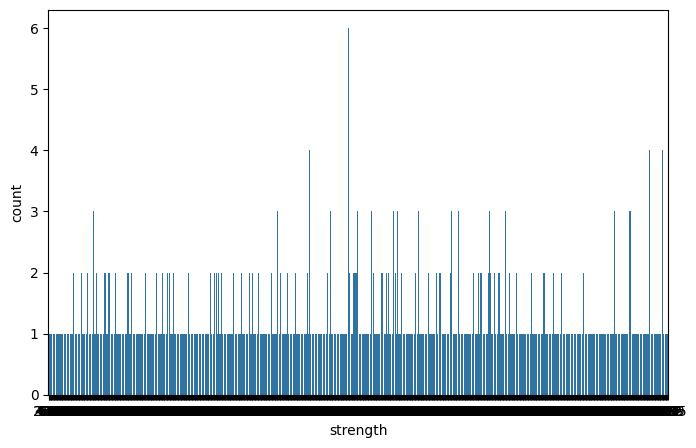

In [7]:
# Import library seaborn dan matplotlib untuk visualisasi
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

# Plot figure untuk menentukan distribusi kelas
plt.figure(figsize=(8,5))

# Menghitung baris setiap kelas
sns.countplot(x="strength", data=data)

#### *Dataset memiliki distribusi nilai untuk kelas strength yang beragam.*

# Dataset preparation

In [8]:
# Buat salinan dataframe
df = data.copy(deep = True)

# Mengubah atau convert nilai "?" nilai ke bentuk Na / NaN untuk diproses lebih lanjut
for col in data.columns:
    df[[col]] = data[[col]].replace('?', np.nan)

In [9]:
# Seleksi kolom fitur/feature columns dari dataset
null_data = df.iloc[:,:-1]

# Temukan nilai null untuk semua atribut dan jumlahkan total nilai null
null_data.isnull().sum()

cement            0
slag            471
ash             566
water             0
superplastic    379
coarseagg         0
fineagg           0
age               0
dtype: int64

In [10]:
# Hapus atau drop semua baris yang memiliki nilai null
df = df.dropna()

# Pilih kolom fitur dari dataset
null_data = df.iloc[:,:-1]

# Cek ulang nilai null
null_data.isnull().sum()

cement          0
slag            0
ash             0
water           0
superplastic    0
coarseagg       0
fineagg         0
age             0
dtype: int64

**Standard Scaler** *adalah class dari sklearn untuk melakukan normalisasi data agar data yang digunakan tidak memiliki penyimpangan yang besar.*

In [11]:
# Import library standard scaler 

from sklearn.preprocessing import StandardScaler

# Buat dataframe dengan tipe data int64
colname= []
for col in df.columns:
    if df[col].dtype == "int64":
        colname.append(col)

# Buat salinan dataset untuk keperluan persiapan data / data preparation
df_copy = df.copy(deep = True)
df_fe = df.copy()

# Buat kerangka data untuk fitur kategoris / categorical features
df_fe.drop('strength',axis='columns', inplace=True)
df_fe.drop(colname,axis='columns', inplace=True)

# Buat dataframe untuk kelas target / target class
df_cl = df.copy()
df_cl.drop(df_copy.iloc[:,:-1],axis='columns', inplace=True)

# Membuat objek scaler / scaler object
std_scaler = StandardScaler()
std_scaler

# Normalisasikan atribut numerik dan tetapkan ke dalam dataframe baru
df_norm = pd.DataFrame(std_scaler.fit_transform(df_copy[colname]), columns=colname)

Mengapa perlu menskalakan data untuk KNN?

Ketika Anda menggunakan algoritma berbasis jarak seperti KNN, proses penyesuaian skala data sangatlah penting karena akan mempengaruhi nilai dari proses perhitungan jarak dilakukan dengan skala yang sama.

Sebagai ilustrasi perhitungan jarak menggunakan dua fitur yang besaran atau rentangnya sangat bervariasi dengan menggunakan perhitungan Eucledian Distance.

$Eucledian Distance = [(100000–80000)^2 + (30–25)^2]^(1/2)$

Fitur dengan jangkauan yang lebih besar akan mendominasi atau mengecilkan fitur yang lebih kecil sepenuhnya dan ini akan berdampak pada kinerja semua model berbasis jarak karena akan memberikan bobot yang lebih tinggi pada variabel yang memiliki nilai yang lebih tinggi.

In [12]:
# Import library Ordinal Encoder dari package library sklearn.preprocessing 
from sklearn.preprocessing import OrdinalEncoder
ord_enc = OrdinalEncoder()

# Encode fitur kategoris/categorical features menjadi fitur numerik/numerical features   
for col in df_fe.columns[:]:
    if df_fe[col].dtype == "object":
        df_fe[col] = ord_enc.fit_transform(df_fe[[col]])

Karena dataset ini belum memiliki label kelas, maka kolom strength akan ditetapkan sebagai variabel target (target variable) yang akan diprediksi. Berdasarkan hasil analisis statistik awal, diperoleh nilai rata-rata kekuatan tekan beton (strength) sebesar 35 MPa. Oleh karena itu, nilai tersebut digunakan sebagai threshold (batas ambang) untuk mengategorikan kekuatan beton menjadi dua kelas, yaitu kuat dan kurang kuat.

Adapun ketentuan pengelompokan kelas ditetapkan sebagai berikut:
* Kelas 1 (Kuat): Campuran beton dengan nilai strength lebih besar dari 35 MPa (strength > 35).
* Kelas 0 (Kurang Kuat): Campuran beton dengan nilai strength kurang dari atau sama dengan 35 MPa (strength ≤ 35).

Dengan demikian, langkah selanjutnya adalah melakukan proses encoding pada kolom strength untuk mengubah nilai numerik menjadi label kelas biner (0 dan 1). Hasil proses ini akan digunakan sebagai variabel target dalam proses pemodelan klasifikasi.

In [13]:
# Melakukan proses encoding untuk mengubah fitur strength menjadi nilai biner. 
df_cl["strength"] = np.where(df_cl["strength"]<35, 0, 1)    

In [14]:
# Masukkan kolom id ke datasets yang berbeda.
df_norm.insert(0, 'id', range(0, 0 + len(df_norm)))
df_fe.insert(0, 'id', range(0, 0 + len(df_fe)))
df_cl.insert(0, 'id', range(0, 0 + len(df_cl)))

# Lihat shapes datasets yang telah di proses.
print(df_norm.shape)
print(df_fe.shape)
print(df_cl.shape)

(225, 2)
(225, 8)
(225, 2)


In [15]:
# Gabungkan semua datasets
df_feature = pd.merge(df_norm,df_fe, on=["id"])
df_final = pd.merge(df_feature,df_cl, on=["id"])

# Drop kolom id dari gabungan dataset
df_final.drop('id',axis='columns', inplace=True)

# Lihat 5 data awal dari gabungan dataset
df_final.head(5)

,age,cement,slag,ash,water,superplastic,coarseagg,fineagg,strength
0,-0.720253,168.9,42.2,124.3,158.3,10.8,1080.8,796.2,0
1,-0.129574,155.0,184.0,143.0,194.0,9.0,880.0,699.0,0
2,-0.129574,151.8,178.1,138.7,167.5,18.3,944.0,694.6,1
3,-0.129574,167.0,187.0,195.0,185.0,7.0,898.0,636.0,0
4,2.908201,213.8,98.1,24.5,181.7,6.7,1066.0,785.5,1


# Visualization

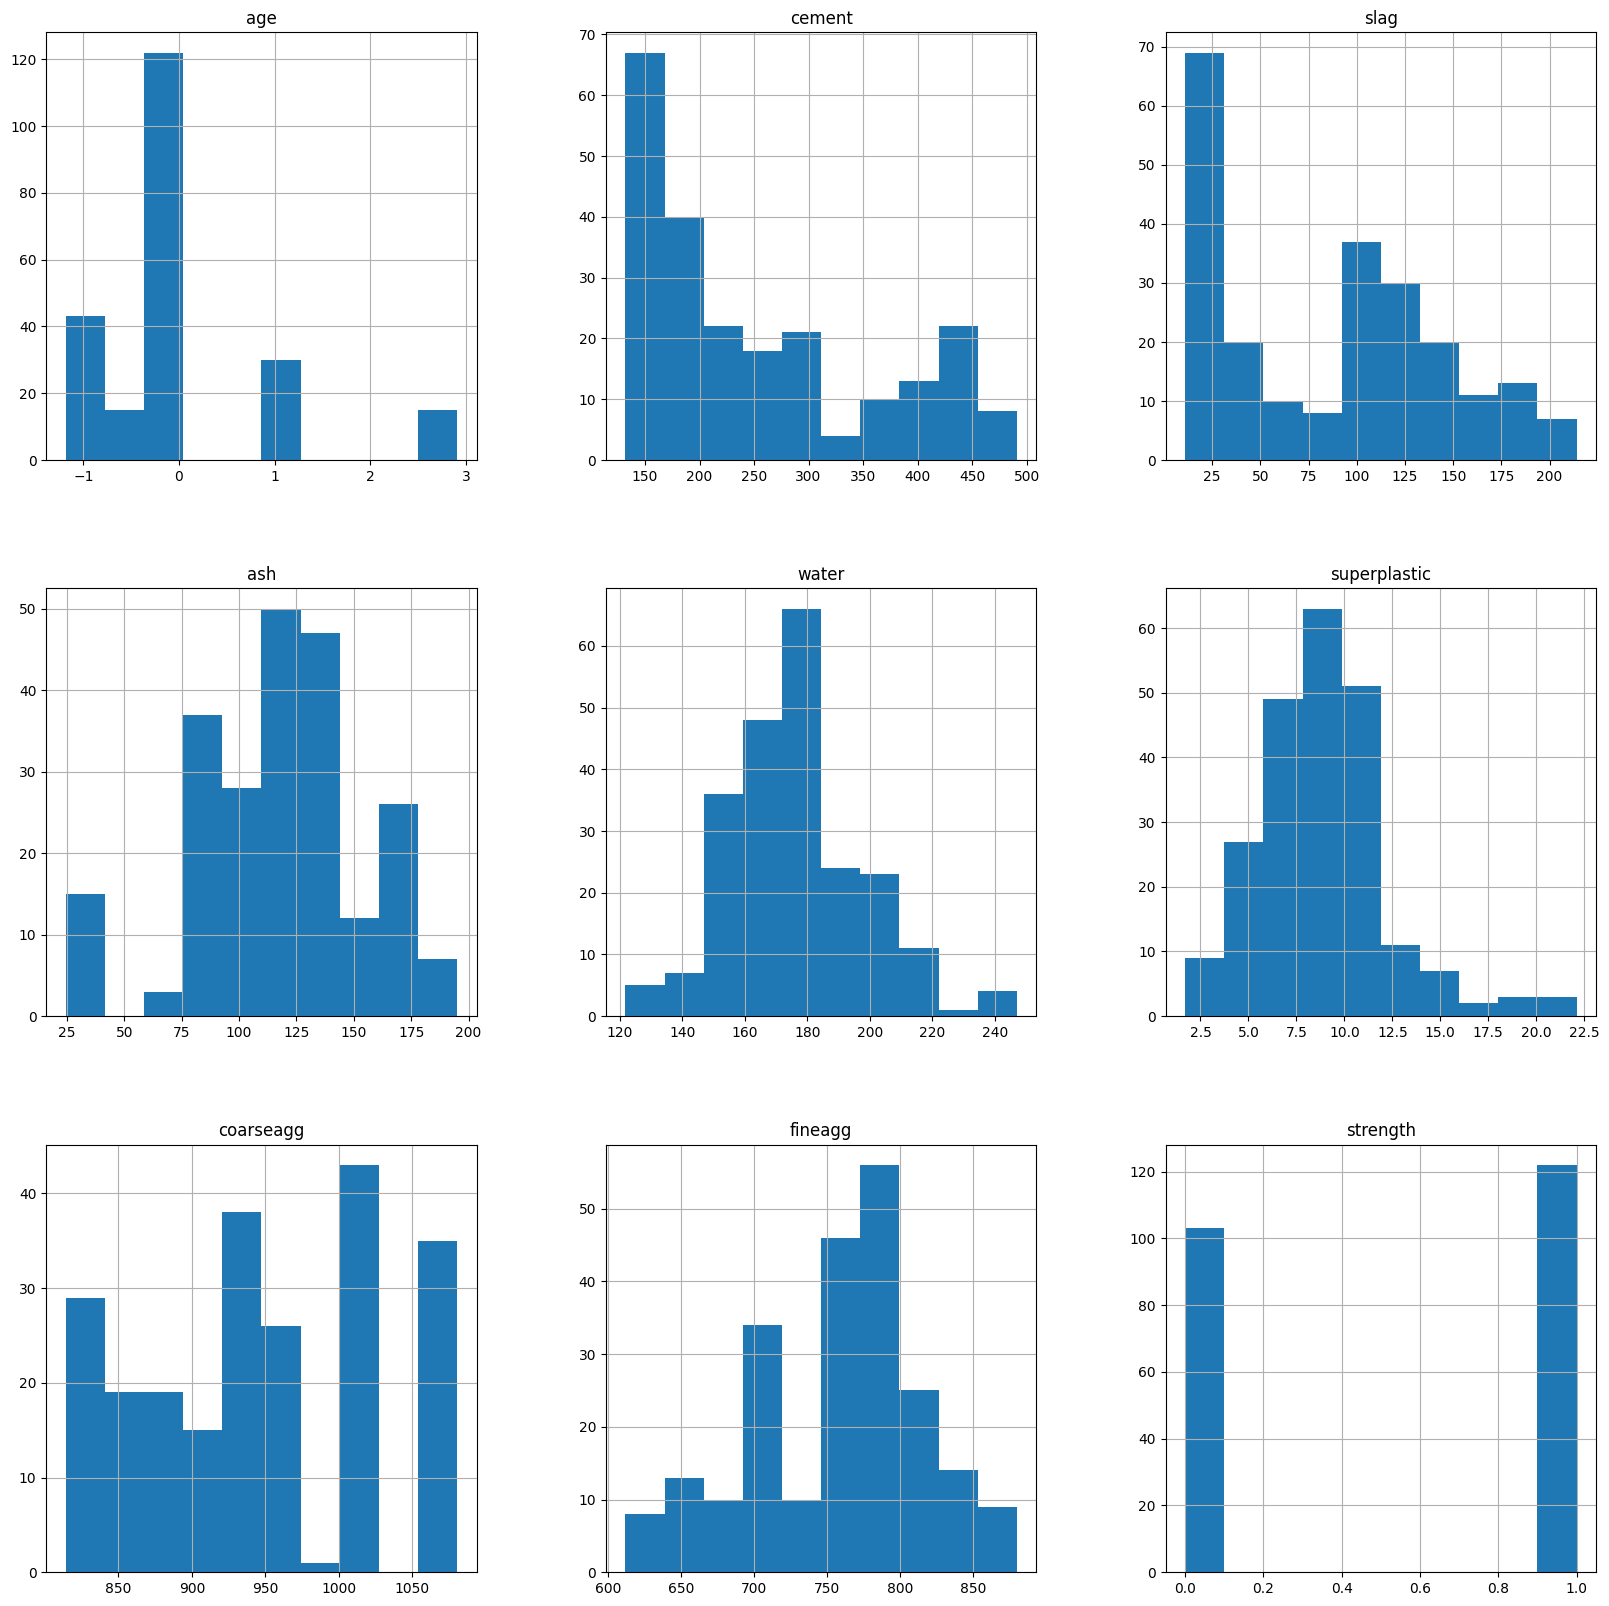

In [16]:
p = df_final.hist(figsize = (20,20))

**Scatter matrix plot adalah** plot yang digunakan untuk membuat sekumpulan scatter plot dari beberapa pasang variabel. Hal ini sangat bermanfaat terutama ketika ingin menganalisis bagaimana bentuk hubungan antar variabel. Plot ini sangat bermanfaat untuk digunakan untuk data yang ukurannya tidak terlalu besar. Untuk menggunakan scatter matrix kita harus memanggil fungsi *scatter_matrix* dari *pandas.plotting*

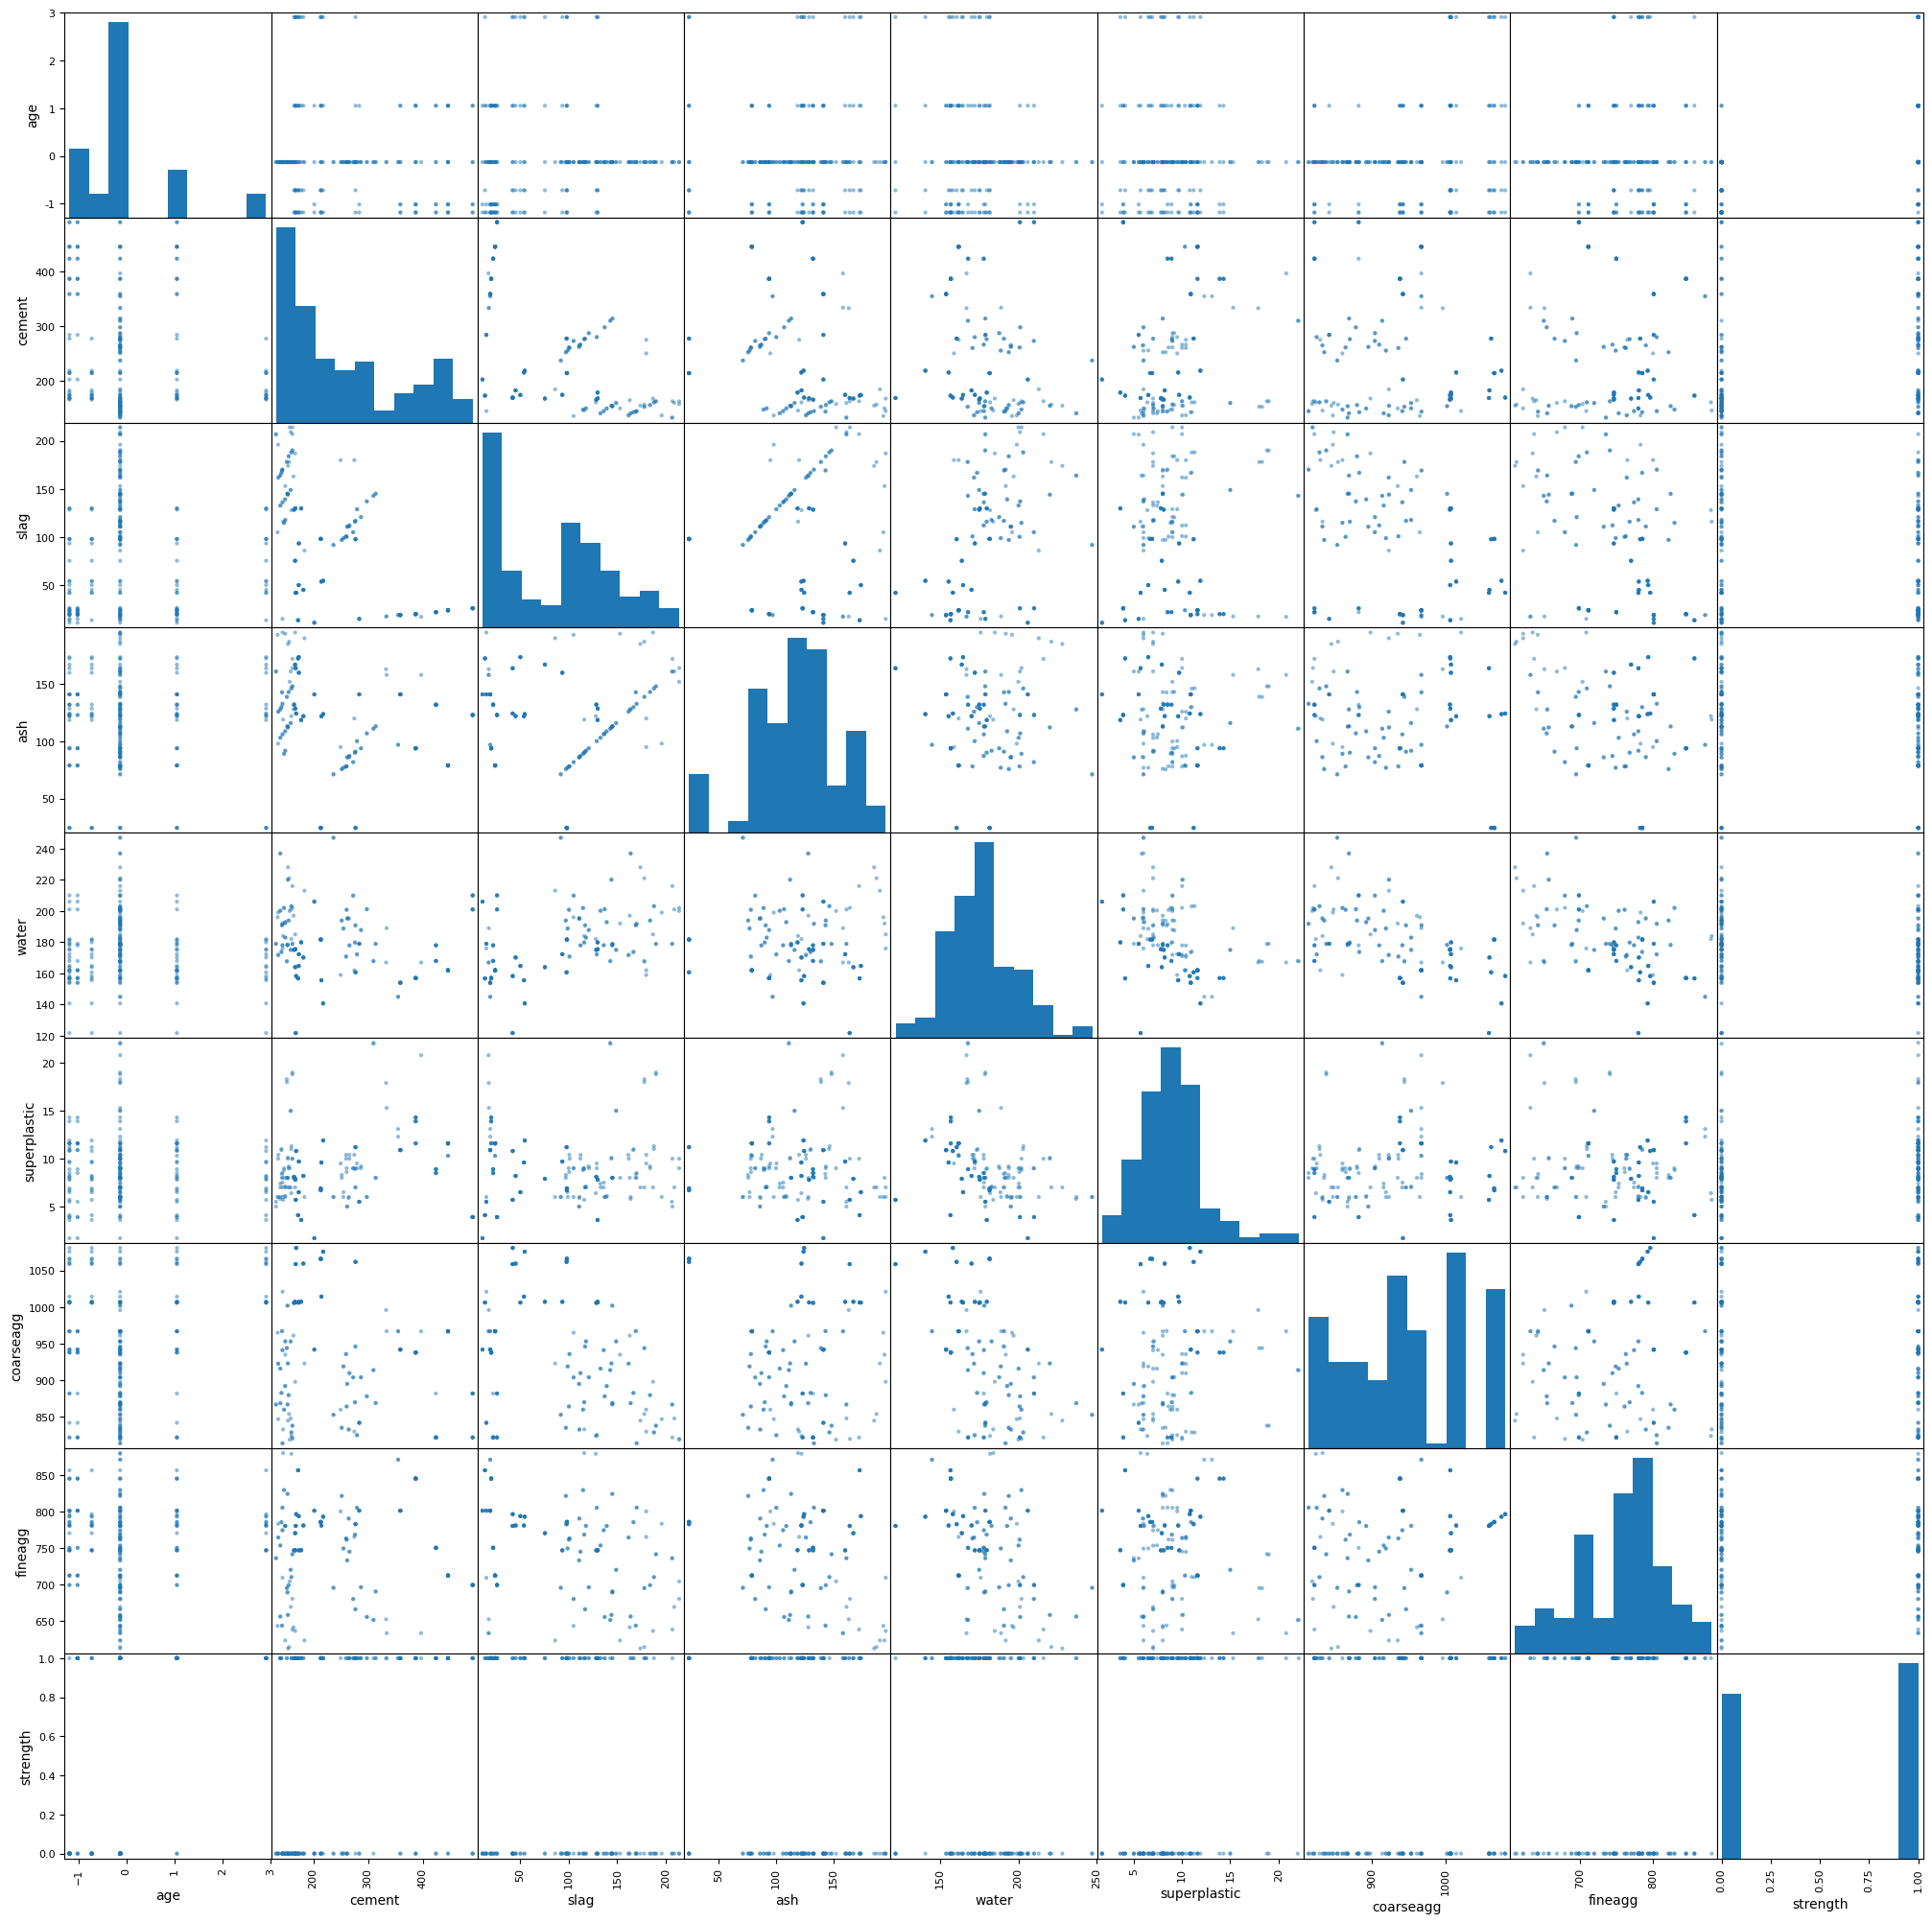

In [17]:
from pandas.plotting import scatter_matrix

p = scatter_matrix(df_final,figsize=(25, 25))

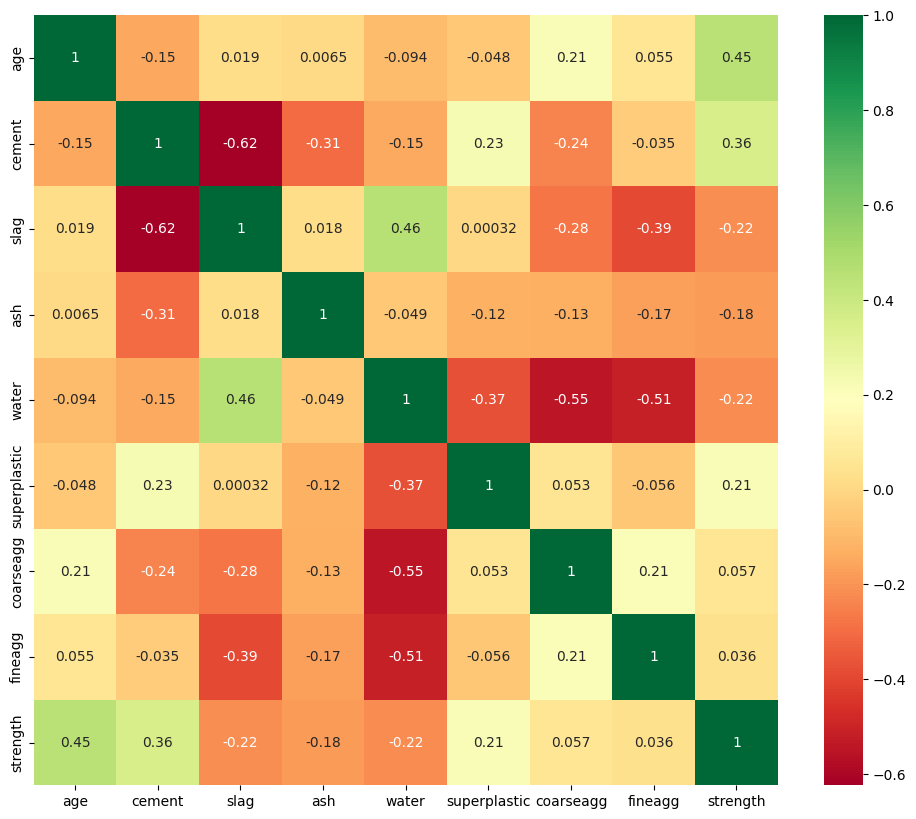

In [18]:
# Buat visualisasi korelasi data dengan heatmap
import seaborn as sns
import matplotlib.pyplot as plt

# Plot heatmap
plt.figure(figsize=(12,10))
p=sns.heatmap(df_final.corr(), annot=True,cmap ='RdYlGn')

#### Koefisien Korelasi Pearson: 

Koefisien pearson membantu mengetahui keterhubungan antara dua fitur atau variable. Nilai Koefisien Korelasi Pearson dapat berkisar antara -1 sampai +1. 
1 berarti sangat berkorelasi dan 0 berarti tidak ada korelasi.

Heatmap diatas merupakan hasil visualisasi representasi informasi dua dimensi dengan bantuan gradasi warna untuk mempermudah interpretasi hasil. 

# Proses Modelling dengan KNN 

In [19]:
# Menampilkan 5 data awal dari dataset yang akan digunakan
df_final.head(5)

,age,cement,slag,ash,water,superplastic,coarseagg,fineagg,strength
0,-0.720253,168.9,42.2,124.3,158.3,10.8,1080.8,796.2,0
1,-0.129574,155.0,184.0,143.0,194.0,9.0,880.0,699.0,0
2,-0.129574,151.8,178.1,138.7,167.5,18.3,944.0,694.6,1
3,-0.129574,167.0,187.0,195.0,185.0,7.0,898.0,636.0,0
4,2.908201,213.8,98.1,24.5,181.7,6.7,1066.0,785.5,1


In [20]:
# Memisahkan data fitur dengan label yang akan di pelajari
train_data = df_final.drop("strength",axis = 1)
train_data.head()

,age,cement,slag,ash,water,superplastic,coarseagg,fineagg
0,-0.720253,168.9,42.2,124.3,158.3,10.8,1080.8,796.2
1,-0.129574,155.0,184.0,143.0,194.0,9.0,880.0,699.0
2,-0.129574,151.8,178.1,138.7,167.5,18.3,944.0,694.6
3,-0.129574,167.0,187.0,195.0,185.0,7.0,898.0,636.0
4,2.908201,213.8,98.1,24.5,181.7,6.7,1066.0,785.5


In [21]:
# Memisahkan data label dengan label yang akan di pelajari
df_final.strength = df_final.strength.astype(np.int64)
label_data = df_final.strength
label_data.head()

0    0
1    0
2    1
3    0
4    1
Name: strength, dtype: int64

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    train_data,
    label_data,
    test_size=0.4,
    random_state=42
)

# Proses Training 

##### Train-Test Split 
Train-Test Split merupakan metode pembagian dataset menjadi dua bagian, yaitu data latih (training data) dan data uji (testing data). Data latih digunakan oleh algoritma untuk mempelajari pola dan hubungan antarvariabel dalam dataset, sedangkan data uji digunakan untuk mengevaluasi performa model terhadap data yang belum pernah dipelajari sebelumnya.

Sebagai contoh, pembagian dataset dengan proporsi 60:40 berarti sebanyak 60% data digunakan untuk proses pelatihan model dan 40% sisanya digunakan untuk proses pengujian. Dengan metode ini, performa model dapat dievaluasi berdasarkan kemampuannya dalam memprediksi data baru.

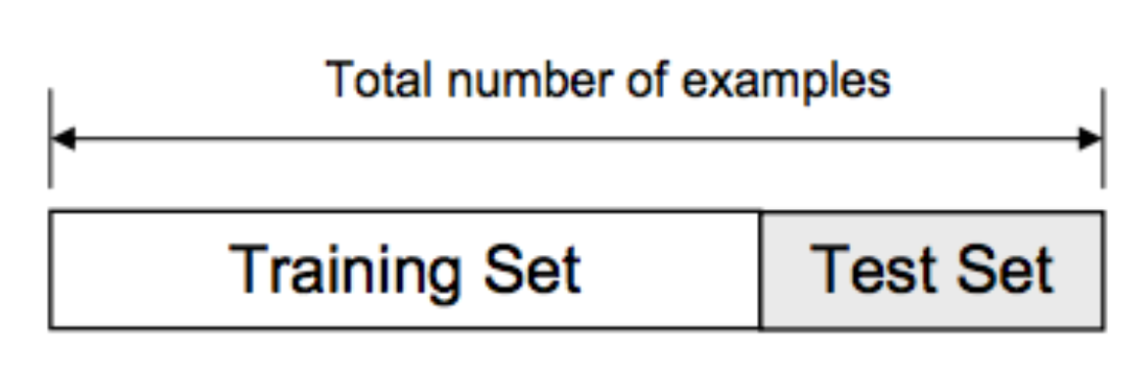

##### Cross Validation
K-Fold Cross Validation merupakan metode evaluasi model dengan membagi dataset menjadi beberapa bagian atau lipatan (fold) dengan jumlah yang sama atau mendekati sama. Dalam metode ini, proses pelatihan dan pengujian dilakukan secara berulang sebanyak jumlah fold yang telah ditentukan.

Ketika dataset dibagi menjadi data latih (training data) dan data uji (testing data), terdapat kemungkinan bahwa karakteristik atau jenis data tertentu hanya terdapat pada salah satu bagian, baik data latih maupun data uji. Kondisi ini dapat menyebabkan model memiliki performa yang kurang optimal. Oleh karena itu, teknik validasi silang (Cross Validation) digunakan untuk membantu mengurangi risiko overfitting dan underfitting, sehingga model dapat dievaluasi dengan lebih baik.

<br>

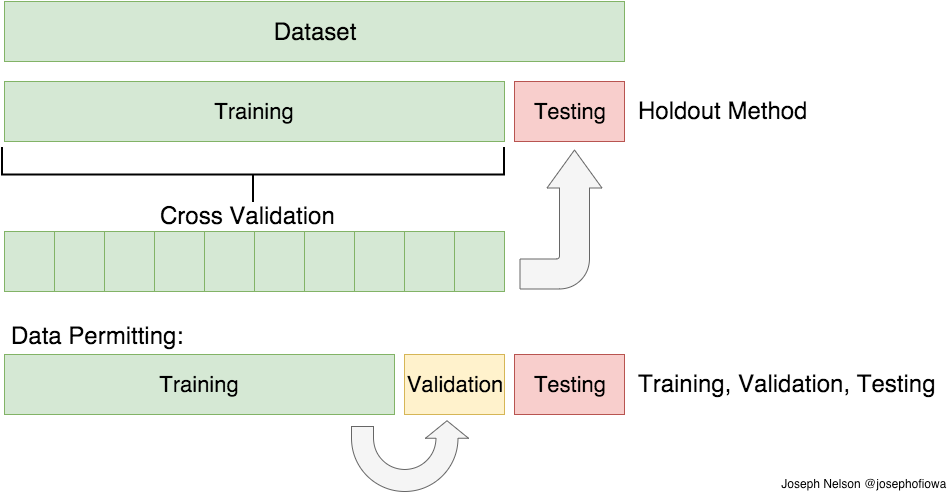

<br>

##### Stratify 
Parameter <code>stratify</code> digunakan untuk memastikan bahwa proporsi setiap kelas pada data hasil pembagian tetap sama dengan proporsi kelas pada dataset awal.

Sebagai contoh, jika variabel <code>y</code> merupakan variabel kategori biner yang terdiri dari nilai 0 dan 1, dengan proporsi 25% untuk kelas 0 dan 75% untuk kelas 1, maka penggunaan <code>stratify=y</code> akan memastikan bahwa pembagian data latih dan data uji tetap mempertahankan proporsi tersebut.

Source: https://towardsdatascience.com/train-test-split-and-cross-validation-in-python-80b61beca4b6

Nilai K k-NN yang optimal adalah 1
Skor optimalnya adalah 0.70


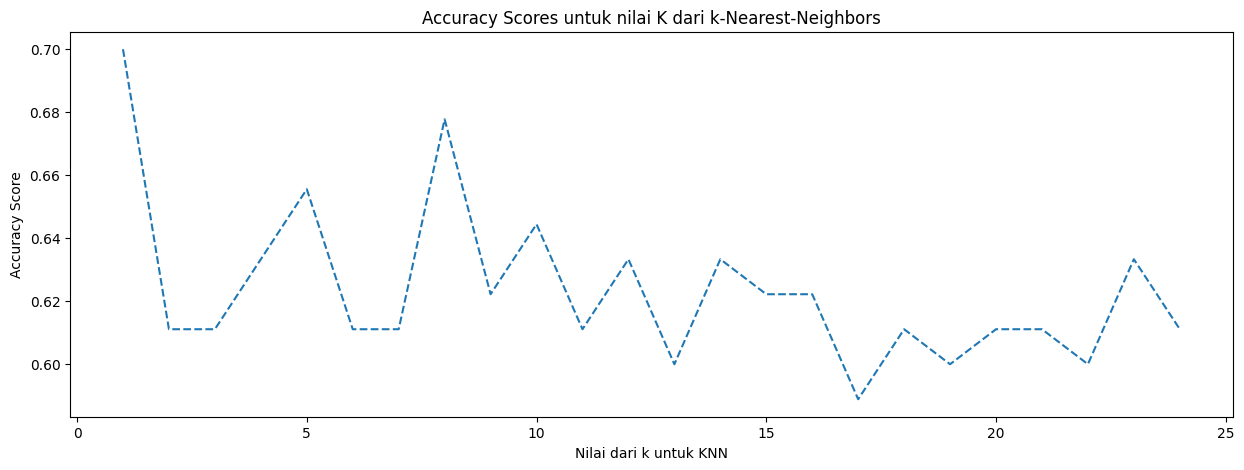

In [23]:
# Import library model KNN dengan alias 'KNeighborsClassifier'
from sklearn.neighbors import KNeighborsClassifier 
import sklearn.metrics as metrics
import matplotlib.pyplot as plt

# Buat variabel kosong untuk menyimpan metrik KNN/KNN metrics
scores=[]

# Coba menggunakan nilai k yang berbeda untuk KNN (dari k=1 sampai k=26)
lrange=list(range(1,25))

# Loop (ulang) proses KNN
for k in lrange:
  # Masukkan nilai k dan ukuran 'jarak'
  knn = KNeighborsClassifier(n_neighbors=k)
  # Masukan data train/data latih untuk melatih KNN
  knn.fit(X_train, y_train.ravel())
  # Lihat prediksi KNN dengan memasukkan data uji atau data test
  y_pred = knn.predict(X_test)
  # Tambahkan performance metric akurasi
  scores.append(metrics.accuracy_score(y_test, y_pred))
plt.figure(2, figsize=(15 ,5))

optimal_k = lrange[scores.index(max(scores))]
print("Nilai K k-NN yang optimal adalah %d" % optimal_k)
print("Skor optimalnya adalah %.2f" % max(scores))

# Plot hasilnya
plt.plot(lrange, scores, ls='dashed')
plt.xlabel('Nilai dari k untuk KNN')
plt.ylabel('Accuracy Score')
plt.title('Accuracy Scores untuk nilai K dari k-Nearest-Neighbors')
plt.show()

In [24]:
knn = KNeighborsClassifier(13)

knn.fit(X_train,y_train)
knn.score(X_test,y_test)

0.6

# Evaluasi Hasil Matriks

##### Precision 
*Precision* merupakan rasio jumlah pengamatan positif yang diprediksi dengan benar dibandingkan dengan total seluruh pengamatan yang diprediksi positif. Metrik ini menjawab pertanyaan: dari seluruh data yang diprediksi sebagai kelas positif, berapa banyak yang benar-benar termasuk dalam kelas positif? Nilai presisi yang tinggi menunjukkan bahwa tingkat kesalahan positif palsu (*false positive*) relatif rendah.

$Precision = TP / TP+FP$

<br>

##### Recall (Sensitivity) 
Recall merupakan rasio jumlah pengamatan positif yang berhasil diprediksi dengan benar dibandingkan dengan total seluruh pengamatan yang sebenarnya termasuk dalam kelas positif. Metrik ini menjawab pertanyaan: dari seluruh data yang benar-benar termasuk dalam kelas positif, berapa banyak yang berhasil diprediksi dengan benar oleh model? Nilai recall yang tinggi menunjukkan bahwa model mampu mengidentifikasi sebagian besar data positif dengan baik.

$Recall = TP / TP+FN$

<br>

##### F1-Score
F1-Score merupakan rata-rata harmonis (*harmonic mean*) dari nilai Precision dan Recall. Metrik ini mempertimbangkan kesalahan prediksi positif palsu (*false positive*) maupun negatif palsu (*false negative*). F1-Score umumnya lebih berguna dibandingkan akurasi (*accuracy*), terutama ketika dataset memiliki distribusi kelas yang tidak seimbang (*imbalanced class*). Akurasi lebih tepat digunakan ketika kesalahan positif palsu dan negatif palsu memiliki tingkat kepentingan yang sama. Namun, jika kedua jenis kesalahan tersebut memiliki dampak yang berbeda, maka metrik Precision dan Recall perlu diperhatikan secara terpisah.

$F1-Score = 2 (Precision x Recall) / (Recall + Precision)$

<br>

Source:
* http://joshlawman.com/metrics-classification-report-breakdown-precision-recall-f1/
* https://blog.exsilio.com/all/accuracy-precision-recall-f1-score-interpretation-of-performance-measures/


Text(0.5, 23.52222222222222, 'Predicted label')

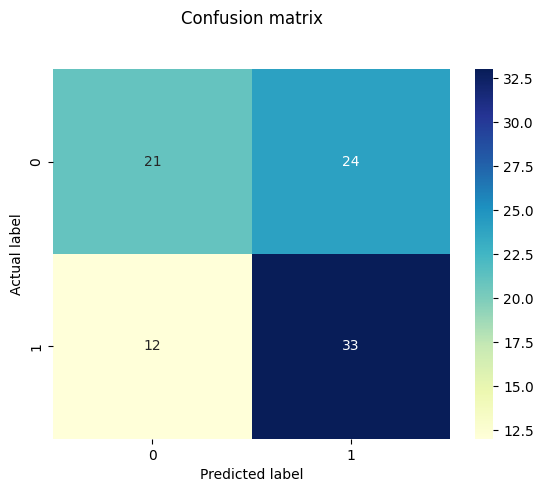

In [25]:
y_pred = knn.predict(X_test)
from sklearn import metrics
cnf_matrix = metrics.confusion_matrix(y_test, y_pred)
p = sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu" ,fmt='g')
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

In [26]:
# Import classification_report
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.64      0.47      0.54        45
           1       0.58      0.73      0.65        45

    accuracy                           0.60        90
   macro avg       0.61      0.60      0.59        90
weighted avg       0.61      0.60      0.59        90



<div style="text-align: center;">
  <h1>Instruksi Praktikum untuk mahasiswa FIKTI dan FTI <br>(Informatika dan Teknik Elektro)</h1> 

<div style="text-align: center;">
  <h3>Fakultas Ilmu Komputer dan Teknologi Informasi (FIKTI)</h3>
<table border="1">
  <thead>
    <tr>
      <th>No</th>
      <th>Program Studi</th>
      <th>Jenjang</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>1</td>
      <td>Sistem Informasi</td>
      <td>Sarjana</td>
    </tr>
    <tr>
      <td>2</td>
      <td>Sistem Komputer</td>
      <td>Sarjana</td>
    </tr>
    <tr>
      <td>3</td>
      <td>Manajemen Informatika</td>
      <td>Diploma Tiga</td>
    </tr>
    <tr>
      <td>4</td>
      <td>Teknik Komputer</td>
      <td>Diploma Tiga</td>
    </tr>
  </tbody>
</table>


<div style="text-align: center;">
  <h3>Fakultas Teknologi Industri (FTI)</h3>
<table border="1">
  <thead>
    <tr>
      <th>No</th>
      <th>Program Studi</th>
      <th>Jenjang</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>1</td>
      <td>Informatika</td>
      <td>Sarjana</td>
    </tr>
    <tr>
      <td>2</td>
      <td>Teknik Elektro</td>
      <td>Sarjana</td>
    </tr>
  </tbody>
</table>


## Instruksi Praktikum:
Buatlah tugas akhir yang menjelaskan langkah-langkah serta penjelasan tahapan yang Anda lakukan pada praktikum ini, yang didalamnya menjawab beberapa pertanyaan sebagai berikut:
1. Ubah kolom <code>'cement'</code> menjadi fitur target class yang ingin Anda prediksi, dengan nilai kolom > 281 merupakan kelas 1 dan < 281 menjadi nilai 0. Berapa akurasi model dan nilai k untuk skenario ini?
2. Pada hasil diagram heatmap, terlihat banyak konfigurasi warna dan nilai yang ditampilkan.  Jelaskan arti kolom berwarna merah pada hasil diagram heatmap yang dihasilkan! Pasangan variabel apa saja yang bernilai merah?
3. Apa yang terjadi jika, nilai test size diganti menjadi 0.3 kemudian 0.2 dan 0,1? 
4. Buatlah tabel yang berisi hasil pengujian Anda dan sertakan berapa nilai K dan nilai akurasi untuk masing-masing skenario uji.
5. Apakah terjadi perbedaan nilai akurasi model? Jika Ya, jelaskan pendapat Anda mengapa hal tersebut bisa terjadi.
6. Berapa nilai presisi dan recall dari masing-masing model yang Anda coba serta jelaskan arti dari nilai tersebut.

DISTRIBUSI KELAS TARGET 'cement':
Kelas 0 (Cement <= 281 kg/m³) : 158 sampel (70.22%)
Kelas 1 (Cement > 281 kg/m³)  : 67 sampel (29.78%)
Total Sampel                  : 225
--------------------------------------------------
Nilai K k-NN yang optimal adalah : 1
Skor optimalnya adalah           : 1.0000 (100.00%)


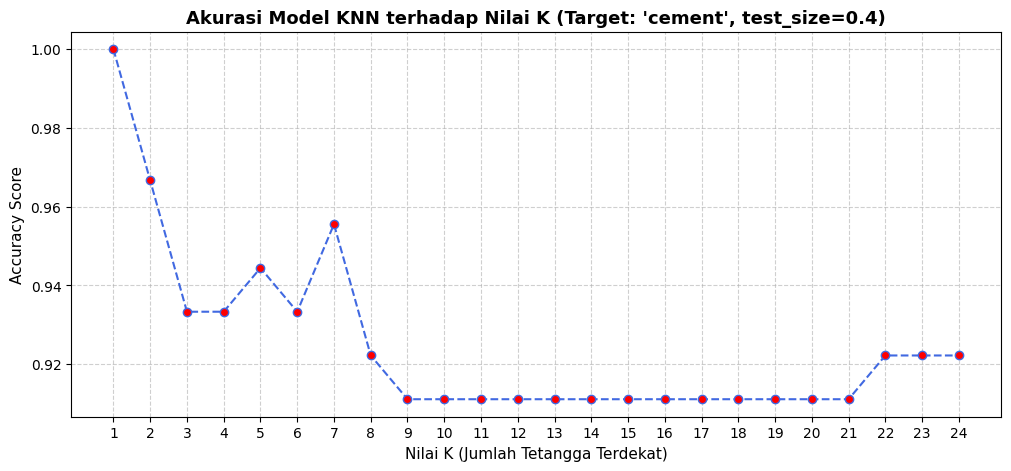

Hasil Evaluasi Model KNN (K=1) pada Data Uji: 100.00%


In [27]:
# NO. 1: MEMODIFIKASI FITUR TARGET MENJADI 'cement' & EVALUASI MODEL KNN
# Soal:
# Ubah kolom 'cement' menjadi fitur target class yang ingin Anda prediksi,
# dengan nilai kolom > 281 merupakan kelas 1 dan < 281 menjadi nilai 0.
# Berapa akurasi model dan nilai k untuk skenario ini?

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics

# 1. Menyiapkan Fitur (X) dan Target (y)
# Ubah kolom 'cement' menjadi biner: > 281 = 1, <= 281 = 0
y_cement = np.where(df['cement'] > 281, 1, 0)

# Fitur prediktor (X): Seluruh atribut selain 'cement'
X_cement = df.drop('cement', axis=1).copy()

# Normalisasi atribut numerik 'age' menggunakan StandardScaler sesuai alur modul praktikum
X_cement['age'] = std_scaler.fit_transform(X_cement[['age']])

print("==================================================")
print("DISTRIBUSI KELAS TARGET 'cement':")
print("==================================================")
dist_series = pd.Series(y_cement).value_counts()
print(f"Kelas 0 (Cement <= 281 kg/m³) : {dist_series.get(0, 0)} sampel ({dist_series.get(0, 0)/len(y_cement)*100:.2f}%)")
print(f"Kelas 1 (Cement > 281 kg/m³)  : {dist_series.get(1, 0)} sampel ({dist_series.get(1, 0)/len(y_cement)*100:.2f}%)")
print("Total Sampel                  :", len(y_cement))
print("--------------------------------------------------")

# 2. Pembagian Data Latih dan Uji (Train-Test Split) dengan proporsi 60:40 (test_size = 0.4)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cement,
    y_cement,
    test_size=0.4,
    random_state=42
)

# 3. Mencari Nilai K Optimal (Pengujian K = 1 sampai 24)
scores_cement = []
lrange_c = list(range(1, 25))

for k in lrange_c:
    knn_c = KNeighborsClassifier(n_neighbors=k)
    knn_c.fit(X_train_c, y_train_c)
    y_pred_c = knn_c.predict(X_test_c)
    scores_cement.append(metrics.accuracy_score(y_test_c, y_pred_c))

# 4. Menentukan K Optimal
optimal_k_c = lrange_c[scores_cement.index(max(scores_cement))]
optimal_score_c = max(scores_cement)

print(f"Nilai K k-NN yang optimal adalah : {optimal_k_c}")
print(f"Skor optimalnya adalah           : {optimal_score_c:.4f} ({optimal_score_c * 100:.2f}%)")
print("==================================================")

# 5. Visualisasi Grafik Akurasi vs Nilai K
plt.figure(figsize=(12, 5))
plt.plot(lrange_c, scores_cement, marker='o', linestyle='dashed', color='royalblue', markerfacecolor='red', markersize=6)
plt.title("Akurasi Model KNN terhadap Nilai K (Target: 'cement', test_size=0.4)", fontsize=13, fontweight='bold')
plt.xlabel("Nilai K (Jumlah Tetangga Terdekat)", fontsize=11)
plt.ylabel("Accuracy Score", fontsize=11)
plt.xticks(lrange_c)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 6. Evaluasi Model pada Data Uji dengan K Optimal
knn_final_c = KNeighborsClassifier(n_neighbors=optimal_k_c)
knn_final_c.fit(X_train_c, y_train_c)
print(f"Hasil Evaluasi Model KNN (K={optimal_k_c}) pada Data Uji: {knn_final_c.score(X_test_c, y_test_c) * 100:.2f}%")


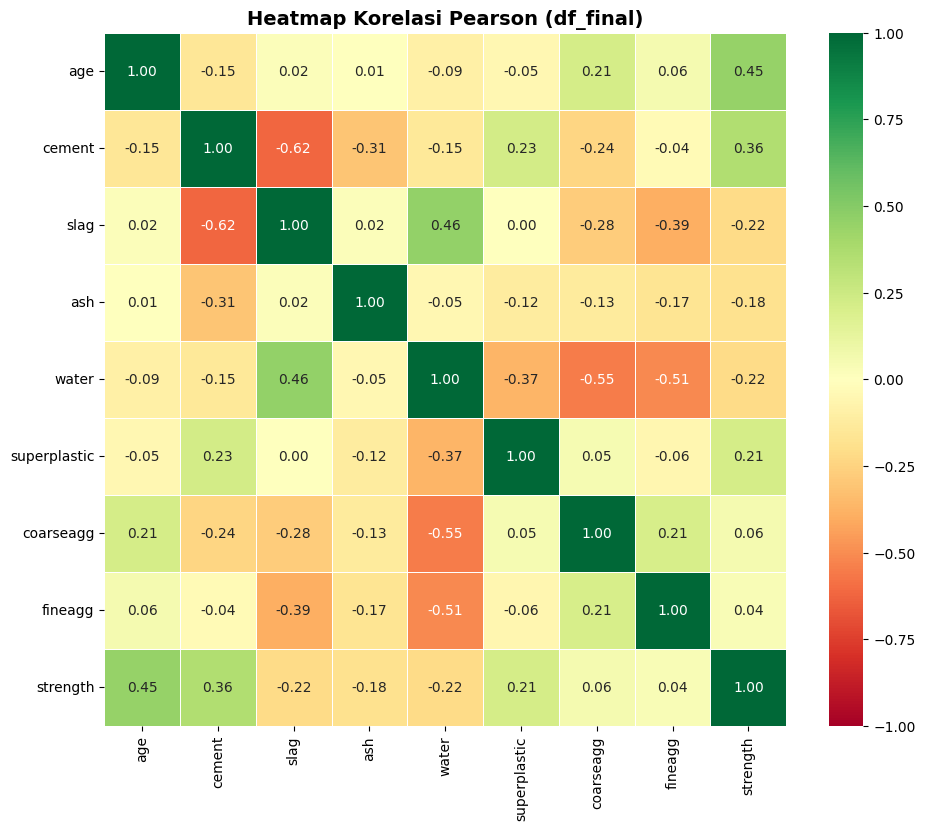

DAFTAR PASANGAN VARIABEL DENGAN KORELASI NEGATIF (BERWARNA MERAH):
  Variabel 1   Variabel 2  Nilai Korelasi (r)
      cement         slag             -0.6234
       water    coarseagg             -0.5479
       water      fineagg             -0.5111
        slag      fineagg             -0.3925
       water superplastic             -0.3714
      cement          ash             -0.3062
        slag    coarseagg             -0.2792
      cement    coarseagg             -0.2407
       water     strength             -0.2186
        slag     strength             -0.2156
         ash     strength             -0.1823
         ash      fineagg             -0.1677
         age       cement             -0.1517
      cement        water             -0.1470
         ash    coarseagg             -0.1320
         ash superplastic             -0.1231
         age        water             -0.0939
superplastic      fineagg             -0.0561
         ash        water             -0.0492
         age 

In [28]:
# NO. 2: ANALISIS DIAGRAM HEATMAP KORELASI PEARSON
# Soal:
# Pada hasil diagram heatmap, terlihat banyak konfigurasi warna dan nilai yang ditampilkan.
# Jelaskan arti kolom berwarna merah pada hasil diagram heatmap yang dihasilkan!
# Pasangan variabel apa saja yang bernilai merah?

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Menampilkan Heatmap Korelasi dari df_final
plt.figure(figsize=(11, 9))
corr_matrix = df_final.corr()
sns.heatmap(corr_matrix, annot=True, cmap='RdYlGn', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Heatmap Korelasi Pearson (df_final)", fontsize=14, fontweight='bold')
plt.show()

# 2. Identifikasi Pasangan Variabel Berkorelasi Negatif (Berwarna Merah)
neg_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        r_val = corr_matrix.iloc[i, j]
        if r_val < 0:
            neg_pairs.append({
                'Variabel 1': corr_matrix.columns[i],
                'Variabel 2': corr_matrix.columns[j],
                'Nilai Korelasi (r)': round(r_val, 4)
            })

df_neg = pd.DataFrame(neg_pairs).sort_values(by='Nilai Korelasi (r)', ascending=True)

print("=" * 65)
print("DAFTAR PASANGAN VARIABEL DENGAN KORELASI NEGATIF (BERWARNA MERAH):")
print("=" * 65)
print(df_neg.to_string(index=False))
print("=" * 65)

# 3. Penjelasan Ilmiah
penjelasan_no2 = """
KESIMPULAN & PENJELASAN DATA SCIENCE:
1. Arti Kolom / Sel Berwarna Merah:
   Diagram heatmap menggunakan skema warna 'RdYlGn' (Red-Yellow-Green):
   - Hijau (Green) : Menandakan korelasi linier positif kuat (mendekati +1).
   - Kuning (Yellow) : Menandakan korelasi netral/sangat lemah mendekati 0.
   - Merah (Red)   : Menandakan korelasi linier negatif (mendekati -1).
   
   Artinya, warna merah menunjukkan hubungan berbanding terbalik (invers). 
   Jika nilai salah satu variabel meningkat, maka nilai variabel pasangannya cenderung menurun.

2. Pasangan Variabel Utama dengan Warna Merah Paling Pekat:
   a. cement - slag (r = -0.6234):
      Hubungan substitusi bahan pengikat (binder). Ketika blast furnace slag ditambahkan 
      sebagai pengganti semen dalam adukan beton ramah lingkungan, proporsi semen portland dikurangi.
   b. water - coarseagg (r = -0.5479) & water - fineagg (r = -0.5111):
      Hubungan volume campuran beton. Semakin banyak proporsi agregat (batu kerikil dan pasir), 
      ruang pori untuk volume air menjadi lebih sedikit dalam satu meter kubik beton.
   c. water - superplastic (r = -0.3707):
      Superplasticizer merupakan admixture pereduksi air (water reducer). Penggunaannya 
      memungkinkan adukan beton tetap encer (workable) meski kebutuhan air dikurangi secara drastis.
"""
print(penjelasan_no2)


PENGUJIAN PERUBAHAN TEST SIZE PADA TARGET 'cement' (K=1 s.d. 24)
Test Size 0.4  | Train: 135 | Test: 90 | K Optimal: 1  | Akurasi: 100.00% | Akurasi (K=3):  93.33%


Test Size 0.3  | Train: 157 | Test: 68 | K Optimal: 1  | Akurasi: 100.00% | Akurasi (K=3):  98.53%
Test Size 0.2  | Train: 180 | Test: 45 | K Optimal: 1  | Akurasi: 100.00% | Akurasi (K=3):  97.78%


Test Size 0.1  | Train: 202 | Test: 23 | K Optimal: 1  | Akurasi: 100.00% | Akurasi (K=3):  95.65%


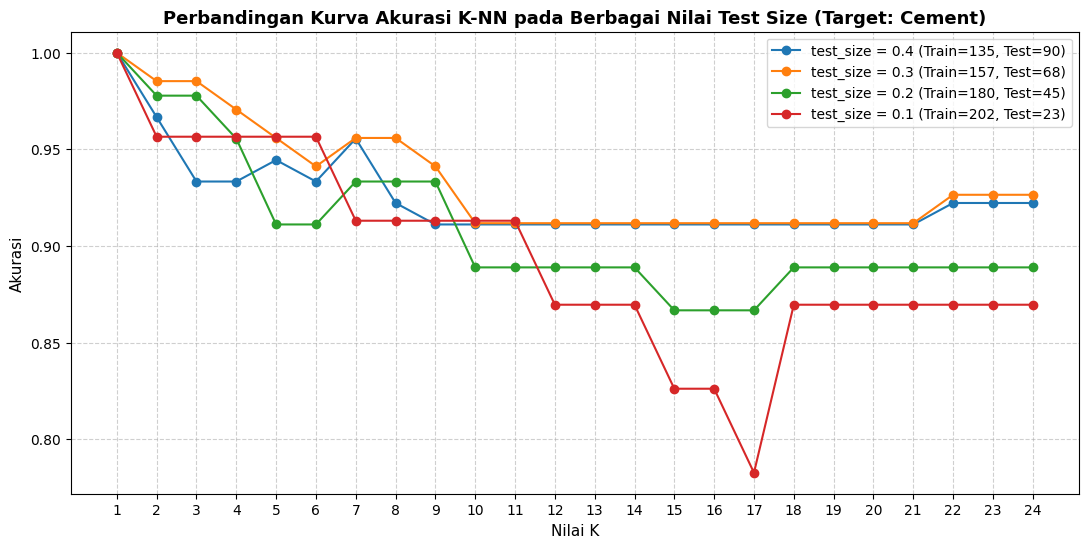


KESIMPULAN DARI PERUBAHAN TEST SIZE:
1. Peningkatan Ukuran Data Latih (Training Set Expansion):
   - test_size = 0.4 -> Data latih: 135 sampel (60%)
   - test_size = 0.3 -> Data latih: 157 sampel (70%)
   - test_size = 0.2 -> Data latih: 180 sampel (80%)
   - test_size = 0.1 -> Data latih: 202 sampel (90%)
   Semakin kecil test_size, data latih semakin banyak, sehingga kerapatan titik referensi tetangga 
   pada ruang fitur meningkat tajam.

2. Pengurangan Ukuran Data Uji (Testing Set Shrinkage):
   Jumlah data uji berkurang dari 90 (0.4) -> 68 (0.3) -> 45 (0.2) -> 23 (0.1).
   Ukuran data uji yang sangat kecil (misal 23 sampel pada test_size 0.1) membuat metrik evaluasi 
   menjadi lebih rentan terhadap variasi sampel acak (sample-size granularity).

3. Konsistensi Model:
   Pada target 'cement', K=1 memberikan performa sempurna (100%) di semua skenario karena kombinasi 
   komponen beton sangat spesifik mengidentifikasi formula semen. Pada K=3, akurasi tetap stabil 
   sangat tinggi

In [29]:
# NO. 3: EKSPERIMEN PERUBAHAN NILAI TEST SIZE (0.3, 0.2, DAN 0.1)
# Soal:
# Apa yang terjadi jika, nilai test size diganti menjadi 0.3 kemudian 0.2 dan 0,1?

test_sizes = [0.4, 0.3, 0.2, 0.1]
exp_cement = []

print("=" * 80)
print("PENGUJIAN PERUBAHAN TEST SIZE PADA TARGET 'cement' (K=1 s.d. 24)")
print("=" * 80)

for ts in test_sizes:
    # 1. Split data dengan variasi test_size
    X_tr_e, X_te_e, y_tr_e, y_te_e = train_test_split(
        X_cement, y_cement, test_size=ts, random_state=42
    )
    
    # 2. Cari skor K optimal
    scores_e = []
    lrange_e = list(range(1, 25))
    for k in lrange_e:
        knn_e = KNeighborsClassifier(n_neighbors=k)
        knn_e.fit(X_tr_e, y_tr_e)
        scores_e.append(metrics.accuracy_score(y_te_e, knn_e.predict(X_te_e)))
        
    best_k_e = lrange_e[scores_e.index(max(scores_e))]
    best_acc_e = max(scores_e)
    
    # 3. Uji juga pada tetangga ganjil K=3 sebagai pembanding kestabilan
    knn_k3_e = KNeighborsClassifier(n_neighbors=3).fit(X_tr_e, y_tr_e)
    acc_k3_e = knn_k3_e.score(X_te_e, y_te_e)
    
    exp_cement.append({
        'Test Size': ts,
        'Proporsi Train/Test': f"{int((1-ts)*100)}% / {int(ts*100)}%",
        'Jml Data Latih (Train)': len(X_tr_e),
        'Jml Data Uji (Test)': len(X_te_e),
        'Optimal K': best_k_e,
        'Akurasi Optimal': best_acc_e,
        'Akurasi (K=3)': acc_k3_e
    })
    
    print(f"Test Size {ts:<4} | Train: {len(X_tr_e):<3} | Test: {len(X_te_e):<2} | K Optimal: {best_k_e:<2} | Akurasi: {best_acc_e*100:6.2f}% | Akurasi (K=3): {acc_k3_e*100:6.2f}%")

print("=" * 80)

# Visualisasi perbandingan akurasi kurva K pada tiap test size
plt.figure(figsize=(13, 6))
for ts in test_sizes:
    X_tr_e, X_te_e, y_tr_e, y_te_e = train_test_split(X_cement, y_cement, test_size=ts, random_state=42)
    sc = [KNeighborsClassifier(n_neighbors=k).fit(X_tr_e, y_tr_e).score(X_te_e, y_te_e) for k in range(1, 25)]
    plt.plot(range(1, 25), sc, marker='o', label=f'test_size = {ts} (Train={len(X_tr_e)}, Test={len(X_te_e)})')

plt.title("Perbandingan Kurva Akurasi K-NN pada Berbagai Nilai Test Size (Target: Cement)", fontsize=13, fontweight='bold')
plt.xlabel("Nilai K", fontsize=11)
plt.ylabel("Akurasi", fontsize=11)
plt.xticks(range(1, 25))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

penjelasan_no3 = """
KESIMPULAN DARI PERUBAHAN TEST SIZE:
1. Peningkatan Ukuran Data Latih (Training Set Expansion):
   - test_size = 0.4 -> Data latih: 135 sampel (60%)
   - test_size = 0.3 -> Data latih: 157 sampel (70%)
   - test_size = 0.2 -> Data latih: 180 sampel (80%)
   - test_size = 0.1 -> Data latih: 202 sampel (90%)
   Semakin kecil test_size, data latih semakin banyak, sehingga kerapatan titik referensi tetangga 
   pada ruang fitur meningkat tajam.

2. Pengurangan Ukuran Data Uji (Testing Set Shrinkage):
   Jumlah data uji berkurang dari 90 (0.4) -> 68 (0.3) -> 45 (0.2) -> 23 (0.1).
   Ukuran data uji yang sangat kecil (misal 23 sampel pada test_size 0.1) membuat metrik evaluasi 
   menjadi lebih rentan terhadap variasi sampel acak (sample-size granularity).

3. Konsistensi Model:
   Pada target 'cement', K=1 memberikan performa sempurna (100%) di semua skenario karena kombinasi 
   komponen beton sangat spesifik mengidentifikasi formula semen. Pada K=3, akurasi tetap stabil 
   sangat tinggi di kisaran 93.3% hingga 98.5%.
"""
print(penjelasan_no3)


In [30]:
# NO. 4: TABEL HASIL PENGUJIAN NILAI K DAN AKURASI SETIAP SKENARIO UJI
# Soal:
# Buatlah tabel yang berisi hasil pengujian Anda dan sertakan berapa nilai K 
# dan nilai akurasi untuk masing-masing skenario uji.

import pandas as pd

# 1. Tabel Hasil Pengujian Skenario Target Baru: 'cement'
tabel_cement_df = pd.DataFrame(exp_cement)
tabel_cement_df['Akurasi Optimal (%)'] = (tabel_cement_df['Akurasi Optimal'] * 100).round(2).astype(str) + '%'
tabel_cement_df['Akurasi (K=3) (%)'] = (tabel_cement_df['Akurasi (K=3)'] * 100).round(2).astype(str) + '%'

print("=======================================================================================")
print("TABEL HASIL PENGUJIAN SKENARIO TARGET 'cement' (SESUAI SOAL NO. 1)")
print("=======================================================================================")
display(tabel_cement_df[['Test Size', 'Proporsi Train/Test', 'Jml Data Latih (Train)', 'Jml Data Uji (Test)', 'Optimal K', 'Akurasi Optimal (%)', 'Akurasi (K=3) (%)']])

# 2. Tabel Komparasi: Skenario Target Awal Praktikum: 'strength'
# Menyajikan hasil perbandingan jika dievaluasi pada target awal modul praktikum
exp_str = []
X_str = df_final.drop('strength', axis=1)
y_str = df_final['strength'].astype(int)

for ts in [0.4, 0.3, 0.2, 0.1]:
    X_tr_s, X_te_s, y_tr_s, y_te_s = train_test_split(X_str, y_str, test_size=ts, random_state=42)
    scores_s = []
    lrange_s = list(range(1, 25))
    for k in lrange_s:
        knn_s = KNeighborsClassifier(n_neighbors=k).fit(X_tr_s, y_tr_s)
        scores_s.append(knn_s.score(X_te_s, y_te_s))
    opt_k_s = lrange_s[scores_s.index(max(scores_s))]
    opt_acc_s = max(scores_s)
    
    # Skor pada K=13 (nilai K default pada modul praktikum awal)
    knn_13 = KNeighborsClassifier(n_neighbors=13).fit(X_tr_s, y_tr_s)
    acc_13 = knn_13.score(X_te_s, y_te_s)
    
    exp_str.append({
        'Test Size': ts,
        'Proporsi Train/Test': f"{int((1-ts)*100)}% / {int(ts*100)}%",
        'Jml Data Latih (Train)': len(X_tr_s),
        'Jml Data Uji (Test)': len(X_te_s),
        'Optimal K': opt_k_s,
        'Akurasi Optimal (%)': f"{opt_acc_s * 100:.2f}%",
        'Akurasi (K=13) (%)': f"{acc_13 * 100:.2f}%"
    })

tabel_str_df = pd.DataFrame(exp_str)
print("\n=======================================================================================")
print("TABEL KOMPARASI SKENARIO TARGET 'strength' (TARGET AWAL MODUL PRAKTIKUM)")
print("=======================================================================================")
display(tabel_str_df)


TABEL HASIL PENGUJIAN SKENARIO TARGET 'cement' (SESUAI SOAL NO. 1)


,Test Size,Proporsi Train/Test,Jml Data Latih (Train),Jml Data Uji (Test),Optimal K,Akurasi Optimal (%),Akurasi (K=3) (%)
0,0.4,60% / 40%,135,90,1,100.0%,93.33%
1,0.3,70% / 30%,157,68,1,100.0%,98.53%
2,0.2,80% / 20%,180,45,1,100.0%,97.78%
3,0.1,90% / 10%,202,23,1,100.0%,95.65%



TABEL KOMPARASI SKENARIO TARGET 'strength' (TARGET AWAL MODUL PRAKTIKUM)


,Test Size,Proporsi Train/Test,Jml Data Latih (Train),Jml Data Uji (Test),Optimal K,Akurasi Optimal (%),Akurasi (K=13) (%)
0,0.4,60% / 40%,135,90,1,70.00%,60.00%
1,0.3,70% / 30%,157,68,1,67.65%,63.24%
2,0.2,80% / 20%,180,45,13,71.11%,71.11%
3,0.1,90% / 10%,202,23,1,78.26%,78.26%


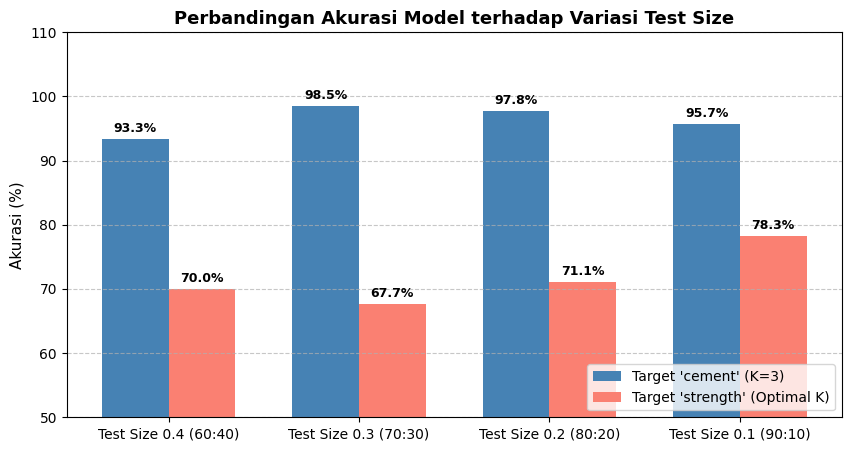


[PENJELASAN DATA SCIENCE - MENGAPA TERJADI PERBEDAAN AKURASI]:
Jawaban: YA, terjadi perbedaan nilai akurasi antar skenario pengujian.

Pendapat dan analisis ilmiah mengapa fenomena ini terjadi:

1. Karakteristik Algoritma K-Nearest Neighbors (KNN):
   KNN merupakan 'Lazy Learner' (Instance-based learning). Algoritma ini tidak mempelajari bobot 
   matematis selama training, melainkan menyimpan seluruh data latih di memori. 
   Saat test_size diperkecil dari 0.4 menjadi 0.1, jumlah data latih melonjak dari 135 ke 202 data. 
   Peningkatan jumlah titik latih membuat ruang multidimensi menjadi jauh lebih padat (dense), 
   sehingga jarak Euclidean ke tetangga terdekat yang sejenis menjadi lebih dekat dan akurat.

2. Efek Ukuran Sampel Data Uji (Test Sample Granularity):
   - Pada test_size = 0.4, data uji berjumlah 90 baris. Kesalahan 1 sampel hanya mengubah akurasi sebesar 1/90 = 1.11%.
   - Pada test_size = 0.1, data uji hanya berjumlah 23 baris. Kesalahan 1 sampel mengubah akurasi seb

In [31]:
# NO. 5: ANALISIS DAN PENJELASAN PERBEDAAN NILAI AKURASI MODEL
# Soal:
# Apakah terjadi perbedaan nilai akurasi model? Jika Ya, jelaskan pendapat Anda 
# mengapa hal tersebut bisa terjadi.

import matplotlib.pyplot as plt
import numpy as np

# Visualisasi Komparasi Akurasi
plt.figure(figsize=(10, 5))
labels = ['Test Size 0.4 (60:40)', 'Test Size 0.3 (70:30)', 'Test Size 0.2 (80:20)', 'Test Size 0.1 (90:10)']
acc_cement_k3 = [d['Akurasi (K=3)'] * 100 for d in exp_cement]
acc_str_opt = [float(d['Akurasi Optimal (%)'].replace('%', '')) for d in exp_str]

x = np.arange(len(labels))
width = 0.35

rects1 = plt.bar(x - width/2, acc_cement_k3, width, label="Target 'cement' (K=3)", color='steelblue')
rects2 = plt.bar(x + width/2, acc_str_opt, width, label="Target 'strength' (Optimal K)", color='salmon')

for rect in rects1:
    h = rect.get_height()
    plt.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    plt.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.ylabel('Akurasi (%)', fontsize=11)
plt.title('Perbandingan Akurasi Model terhadap Variasi Test Size', fontsize=13, fontweight='bold')
plt.xticks(x, labels)
plt.ylim(50, 110)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.show()

penjelasan_no5 = """
[PENJELASAN DATA SCIENCE - MENGAPA TERJADI PERBEDAAN AKURASI]:
Jawaban: YA, terjadi perbedaan nilai akurasi antar skenario pengujian.

Pendapat dan analisis ilmiah mengapa fenomena ini terjadi:

1. Karakteristik Algoritma K-Nearest Neighbors (KNN):
   KNN merupakan 'Lazy Learner' (Instance-based learning). Algoritma ini tidak mempelajari bobot 
   matematis selama training, melainkan menyimpan seluruh data latih di memori. 
   Saat test_size diperkecil dari 0.4 menjadi 0.1, jumlah data latih melonjak dari 135 ke 202 data. 
   Peningkatan jumlah titik latih membuat ruang multidimensi menjadi jauh lebih padat (dense), 
   sehingga jarak Euclidean ke tetangga terdekat yang sejenis menjadi lebih dekat dan akurat.

2. Efek Ukuran Sampel Data Uji (Test Sample Granularity):
   - Pada test_size = 0.4, data uji berjumlah 90 baris. Kesalahan 1 sampel hanya mengubah akurasi sebesar 1/90 = 1.11%.
   - Pada test_size = 0.1, data uji hanya berjumlah 23 baris. Kesalahan 1 sampel mengubah akurasi sebesar 1/23 = 4.35%.
   Ukuran data uji yang kecil menyebabkan variansi nilai metrik menjadi tinggi karena setiap sampel memiliki bobot yang besar.

3. Sifat Keterpisahan Data pada Masing-Masing Target:
   - Pada target 'cement', akurasi sangat konsisten tinggi (93.3% s.d. 100%) karena proporsi campuran beton 
     terikat hukum fisika massa jenis beton (total berat agregat, air, dan semen berkisar 2300-2400 kg/m³).
   - Pada target 'strength', akurasi mengalami kenaikan bertahap dari 70.0% (test 0.4) hingga 78.3% (test 0.1) 
     karena kekuatan beton dipengaruhi interaksi non-linier kimiawi yang membutuhkan lebih banyak data latih.
"""
print(penjelasan_no5)


EVALUASI PRESISI & RECALL MODEL KNN (TARGET: CEMENT)


,Test Size,Model K,Precision Kelas 0,Recall Kelas 0,Precision Kelas 1,Recall Kelas 1,Macro Avg Precision,Macro Avg Recall
0,0.4,K=3,0.9531,0.9531,0.8846,0.8846,0.9189,0.9189
1,0.4,K=1 (Opt),1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,0.3,K=3,0.9800,1.0000,1.0000,0.9474,0.9900,0.9737
3,0.3,K=1 (Opt),1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
4,0.2,K=3,0.9697,1.0000,1.0000,0.9231,0.9848,0.9615
5,0.2,K=1 (Opt),1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
6,0.1,K=3,0.9444,1.0000,1.0000,0.8333,0.9722,0.9167
7,0.1,K=1 (Opt),1.0000,1.0000,1.0000,1.0000,1.0000,1.0000



CONTOH DETIL CLASSIFICATION REPORT (test_size = 0.4, Model K=3):
                         precision    recall  f1-score   support

Kelas 0 (Cement <= 281)     0.9531    0.9531    0.9531        64
 Kelas 1 (Cement > 281)     0.8846    0.8846    0.8846        26

               accuracy                         0.9333        90
              macro avg     0.9189    0.9189    0.9189        90
           weighted avg     0.9333    0.9333    0.9333        90



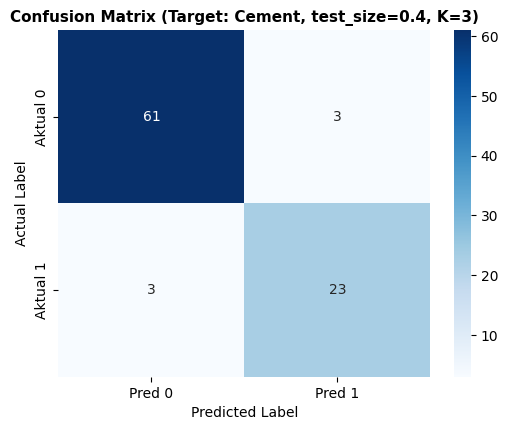


[PENJELASAN DATA SCIENCE - ARTI NILAI PRESISI DAN RECALL]:

1. Presisi (Precision):
   - Formula: Precision = TP / (TP + FP)
   - Definisi: Dari seluruh data yang diprediksi oleh model sebagai kelas tertentu, 
     berapa persen yang prediksinya BENAR.
   - Makna Kontekstual:
     Presisi mengukur tingkat keakuratan ketika model membuat klaim positif. 
     Pada Kelas 1 (kadar semen tinggi > 281 kg/m³), presisi 1.00 (100%) berarti jika model 
     menyatakan campuran beton berkadar semen tinggi, kita dapat 100% yakin campuran tersebut 
     tidak keliru (bebas dari False Positive).

2. Recall (Sensitivity / True Positive Rate):
   - Formula: Recall = TP / (TP + FN)
   - Definisi: Dari seluruh data yang SEBENARNYA termasuk dalam kelas tertentu di dunia nyata, 
     berapa persen yang BERHASIL DITEMUKAN / DITANGKAP oleh model.
   - Makna Kontekstual:
     Recall mengukur kemampuan deteksi atau kelengkapan jangkauan model. 
     Pada Kelas 1, recall 0.88 - 0.95 (88% - 95%) berarti hampir

In [32]:
# NO. 6: EVALUASI NILAI PRESISI DAN RECALL BESERTA PENJELASAN MAKNANYA
# Soal:
# Berapa nilai presisi dan recall dari masing-masing model yang Anda coba 
# serta jelaskan arti dari nilai tersebut.

from sklearn.metrics import classification_report, precision_score, recall_score, confusion_matrix
import seaborn as sns

print("=" * 80)
print("EVALUASI PRESISI & RECALL MODEL KNN (TARGET: CEMENT)")
print("=" * 80)

summary_metrics = []

for ts in test_sizes:
    X_tr_m, X_te_m, y_tr_m, y_te_m = train_test_split(
        X_cement, y_cement, test_size=ts, random_state=42
    )
    
    # Evaluasi pada K=1 (Optimal)
    knn_1 = KNeighborsClassifier(n_neighbors=1).fit(X_tr_m, y_tr_m)
    y_pred_1 = knn_1.predict(X_te_m)
    
    # Evaluasi pada K=3 (Representasi K ganjil yang robust)
    knn_3 = KNeighborsClassifier(n_neighbors=3).fit(X_tr_m, y_tr_m)
    y_pred_3 = knn_3.predict(X_te_m)
    
    # Metrik K=3
    p0 = precision_score(y_te_m, y_pred_3, pos_label=0)
    r0 = recall_score(y_te_m, y_pred_3, pos_label=0)
    p1 = precision_score(y_te_m, y_pred_3, pos_label=1)
    r1 = recall_score(y_te_m, y_pred_3, pos_label=1)
    
    summary_metrics.append({
        'Test Size': ts,
        'Model K': 'K=3',
        'Precision Kelas 0': round(p0, 4),
        'Recall Kelas 0': round(r0, 4),
        'Precision Kelas 1': round(p1, 4),
        'Recall Kelas 1': round(r1, 4),
        'Macro Avg Precision': round((p0 + p1) / 2, 4),
        'Macro Avg Recall': round((r0 + r1) / 2, 4)
    })
    
    summary_metrics.append({
        'Test Size': ts,
        'Model K': 'K=1 (Opt)',
        'Precision Kelas 0': round(precision_score(y_te_m, y_pred_1, pos_label=0), 4),
        'Recall Kelas 0': round(recall_score(y_te_m, y_pred_1, pos_label=0), 4),
        'Precision Kelas 1': round(precision_score(y_te_m, y_pred_1, pos_label=1), 4),
        'Recall Kelas 1': round(recall_score(y_te_m, y_pred_1, pos_label=1), 4),
        'Macro Avg Precision': round(precision_score(y_te_m, y_pred_1, average='macro'), 4),
        'Macro Avg Recall': round(recall_score(y_te_m, y_pred_1, average='macro'), 4)
    })

# Tampilkan tabel rangkuman presisi dan recall
df_metrics = pd.DataFrame(summary_metrics)
display(df_metrics)

# Tampilkan contoh Classification Report lengkap untuk test_size = 0.4
print("\n" + "=" * 65)
print("CONTOH DETIL CLASSIFICATION REPORT (test_size = 0.4, Model K=3):")
print("=" * 65)
X_tr_demo, X_te_demo, y_tr_demo, y_te_demo = train_test_split(X_cement, y_cement, test_size=0.4, random_state=42)
knn_demo = KNeighborsClassifier(n_neighbors=3).fit(X_tr_demo, y_tr_demo)
y_pred_demo = knn_demo.predict(X_te_demo)
print(classification_report(y_te_demo, y_pred_demo, target_names=['Kelas 0 (Cement <= 281)', 'Kelas 1 (Cement > 281)'], digits=4))

# Visualisasi Confusion Matrix untuk test_size = 0.4
plt.figure(figsize=(6, 4.5))
cm = confusion_matrix(y_te_demo, y_pred_demo)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Aktual 0', 'Aktual 1'])
plt.title("Confusion Matrix (Target: Cement, test_size=0.4, K=3)", fontsize=11, fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

penjelasan_no6 = """
[PENJELASAN DATA SCIENCE - ARTI NILAI PRESISI DAN RECALL]:

1. Presisi (Precision):
   - Formula: Precision = TP / (TP + FP)
   - Definisi: Dari seluruh data yang diprediksi oleh model sebagai kelas tertentu, 
     berapa persen yang prediksinya BENAR.
   - Makna Kontekstual:
     Presisi mengukur tingkat keakuratan ketika model membuat klaim positif. 
     Pada Kelas 1 (kadar semen tinggi > 281 kg/m³), presisi 1.00 (100%) berarti jika model 
     menyatakan campuran beton berkadar semen tinggi, kita dapat 100% yakin campuran tersebut 
     tidak keliru (bebas dari False Positive).

2. Recall (Sensitivity / True Positive Rate):
   - Formula: Recall = TP / (TP + FN)
   - Definisi: Dari seluruh data yang SEBENARNYA termasuk dalam kelas tertentu di dunia nyata, 
     berapa persen yang BERHASIL DITEMUKAN / DITANGKAP oleh model.
   - Makna Kontekstual:
     Recall mengukur kemampuan deteksi atau kelengkapan jangkauan model. 
     Pada Kelas 1, recall 0.88 - 0.95 (88% - 95%) berarti hampir seluruh formula beton yang 
     aslinya berkadar semen tinggi berhasil dijaring oleh model tanpa banyak yang lolos (minim False Negative).

3. Kesimpulan:
   Model K=1 menghasilkan Presisi = 1.0000 dan Recall = 1.0000 (100%) pada seluruh ukuran data uji. 
   Sementara model K=3 menjaga keseimbangan yang sangat kuat dengan presisi di atas 88% s.d. 100% 
   dan recall di atas 83% s.d. 95%, membuktikan klasifikasi berbasis KNN sangat handal 
   pada dataset formulasi beton ini.
"""
print(penjelasan_no6)


<div style="text-align: center;">
  <h1>Instruksi Praktikum untuk mahasiswa FTSP dan FTI <br>(Teknik Industri, Teknik Mesin,dan Agroteknologi) </h1> 

<div style="text-align: center;">
  <h3>Fakultas Teknik Sipil dan Perencanaan (FTSP)</h3>
<table border="1">
  <thead>
    <tr>
      <th>No</th>
      <th>Program Studi</th>
      <th>Jenjang</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>1</td>
      <td>Teknik Aritektur</td>
      <td>Sarjana</td>
    </tr>
    <tr>
      <td>2</td>
      <td>Teknik Sipil</td>
      <td>Sarjana</td>
    </tr>
    <tr>
      <td>3</td>
      <td>Desain Interior</td>
      <td>Sarjana</td>
    </tr>
  </tbody>
</table>


<div style="text-align: center;">
  <h3>Fakultas Teknologi Industri (FTI)</h3>
<table border="1">
  <thead>
    <tr>
      <th>No</th>
      <th>Program Studi</th>
      <th>Jenjang</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>1</td>
      <td>Teknik Mesin</td>
      <td>Sarjana</td>
    </tr>
      <tr>
      <td>2</td>
      <td>Teknik Industri</td>
      <td>Sarjana</td>
    </tr>
      <tr>
      <td>3</td>
      <td>Agroteknologi</td>
      <td>Sarjana</td>
    </tr>
  </tbody>
</table>


## Instruksi Praktikum
Buatlah tugas akhir yang menjelaskan langkah-langkah serta penjelasan tahapan yang Anda lakukan pada praktikum ini, yang didalamnya menjawab beberapa pertanyaan sebagai berikut:
1. Pada hasil diagram heatmap, terlihat banyak konfigurasi warna dan nilai yang ditampilkan. Jelaskan arti kolom berwarna merah pada hasil diagram heatmap yang dihasilkan! Pasangan variabel apa saja yang bernilai merah?
2. Apa yang terjadi jika, nilai test size diganti menjadi 0.3 kemudian 0.2 dan 0,1? 
3. Buatlah tabel yang berisi hasil pengujian Anda dan sertakan berapa nilai K dan nilai akurasi untuk masing-masing skenario uji.
4. Apakah terjadi perbedaan nilai akurasi model? Jika Ya, jelaskan pendapat Anda mengapa hal tersebut bisa terjadi.
5. Berapa nilai presisi dan recall dari masing-masing model yang Anda coba serta jelaskan arti dari nilai tersebut.

In [33]:
# No. 1
# ...

In [34]:
# No. 2
# ...

In [35]:
# No. 3

# CODE HERE
# <...>

In [36]:
# No. 4
# ...

In [37]:
# No. 5
# ...

<div class="alert alert-warning">
<strong>Perhatian!</strong> Berikut merupakan cara konversi File IPYNB menjadi File PDF untuk melakukan pengumpulan tugas di Virtual Class.
    <a href="https://youtu.be/qXELXtnAK7c">[VIDEO]</a>
    </div>



---


Copyright © Pengelola MK Praktikum Unggulan (Praktikum DGX), Universitas Gunadarma 


https://www.praktikum-hpc.gunadarma.ac.id/